# AE 312H: Computational Methods in Engineering
## Computer Assignment 4 - LU Decomposition (Crout's Method)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

## Functions used in both questions
Crout decomposition, forward substitution and backward substitution are written once here and reused for Q1 and Q2.

In [2]:
def crout_lu(A, verbose=True):
    n = A.shape[0]
    L = np.zeros((n, n))
    U = np.zeros((n, n))

    for j in range(n):
        for i in range(j, n):
            s = 0.0
            for k in range(j):
                s += L[i, k] * U[k, j]
            L[i, j] = A[i, j] - s
            if verbose:
                print(f"L[{i+1},{j+1}] = A[{i+1},{j+1}] - {s:.6f} = {L[i, j]:.6f}")

        if abs(L[j, j]) < 1e-12:
            print(f"WARNING: pivot L[{j+1},{j+1}] = {L[j, j]:.3e} is (almost) zero")
            if j < n - 1:
                raise ValueError("zero pivot, Crout without pivoting fails")

        U[j, j] = 1.0
        for i in range(j + 1, n):
            s = 0.0
            for k in range(j):
                s += L[j, k] * U[k, i]
            U[j, i] = (A[j, i] - s) / L[j, j]
            if verbose:
                print(f"U[{j+1},{i+1}] = (A[{j+1},{i+1}] - {s:.6f}) / L[{j+1},{j+1}] = {U[j, i]:.6f}")
        if verbose:
            print()
    return L, U


def forward_sub(L, b, verbose=True):
    n = len(b)
    y = np.zeros(n)
    for i in range(n):
        s = 0.0
        for k in range(i):
            s += L[i, k] * y[k]
        if abs(L[i, i]) < 1e-12:
            raise ZeroDivisionError(f"L[{i+1},{i+1}] is zero, cannot do forward substitution")
        y[i] = (b[i] - s) / L[i, i]
        if verbose:
            print(f"y[{i+1}] = ({b[i]:.6f} - {s:.6f}) / {L[i, i]:.6f} = {y[i]:.6f}")
    return y


def backward_sub(U, y, verbose=True):
    n = len(y)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        s = 0.0
        for k in range(i + 1, n):
            s += U[i, k] * x[k]
        x[i] = (y[i] - s) / U[i, i]
        if verbose:
            print(f"x[{i+1}] = ({y[i]:.6f} - {s:.6f}) / {U[i, i]:.6f} = {x[i]:.6f}")
    return x

---
# Q1. Aircraft pitching-moment characteristics

Model: $C_m = C_{m0} + C_{m\alpha}\,\alpha + C_{m\delta_e}\,\delta_e$ (angles in radians)

In [3]:
# wind tunnel data
V = np.array([50.0, 60.0, 70.0])           # m/s
alpha_deg = np.array([2.0, 6.0, 10.0])     # deg
de_deg = np.array([-1.0, 2.0, 5.0])        # deg
M = np.array([8.2773, -5.9759, -32.4914])  # N m

rho = 1.225   # kg/m^3
S = 0.5       # m^2
c = 0.3       # m

In [4]:
# 1) dynamic pressure q = 0.5 rho V^2
q = 0.5 * rho * V**2

# 2) Cm = M / (q S c)
Cm = M / (q * S * c)

print("Test    V (m/s)    q (Pa)        Cm")
for i in range(3):
    print(f"{i+1:3d}    {V[i]:6.1f}    {q[i]:10.4f}    {Cm[i]:10.6f}")

Test    V (m/s)    q (Pa)        Cm
  1      50.0     1531.2500      0.036037
  2      60.0     2205.0000     -0.018068
  3      70.0     3001.2500     -0.072173


In [5]:
# angles to radians (important!)
alpha = np.radians(alpha_deg)
de = np.radians(de_deg)

# A x = b, with x = [Cm0, Cm_alpha, Cm_de]
A = np.column_stack((np.ones(3), alpha, de))
b = Cm.copy()

print("Equations:")
for i in range(3):
    print(f"  Cm0 + ({alpha[i]:.6f}) Cm_alpha + ({de[i]:.6f}) Cm_de = {b[i]:.6f}")

print("\nA =\n", A)
print("\nb =", b)

Equations:
  Cm0 + (0.034907) Cm_alpha + (-0.017453) Cm_de = 0.036037
  Cm0 + (0.104720) Cm_alpha + (0.034907) Cm_de = -0.018068
  Cm0 + (0.174533) Cm_alpha + (0.087266) Cm_de = -0.072173

A =
 [[ 1.        0.034907 -0.017453]
 [ 1.        0.10472   0.034907]
 [ 1.        0.174533  0.087266]]

b = [ 0.036037 -0.018068 -0.072173]


### Check of the matrix before decomposing
The three test points lie on a straight line in the ($\alpha$, $\delta_e$) plane ($\alpha$ goes 2, 6, 10 and $\delta_e$ goes -1, 2, 5, both in equal steps), so the rows of $A$ may be linearly dependent. Checking the determinant and rank.

In [6]:
print("det(A)  =", np.linalg.det(A))
print("rank(A) =", np.linalg.matrix_rank(A))
print("row1 - 2*row2 + row3 =", A[0] - 2*A[1] + A[2])

det(A)  = 9.68852360557951e-19
rank(A) = 2
row1 - 2*row2 + row3 = [ 0. -0.  0.]


In [7]:
L, U = crout_lu(A)

print("L =\n", L)
print("\nU =\n", U)

L[1,1] = A[1,1] - 0.000000 = 1.000000
L[2,1] = A[2,1] - 0.000000 = 1.000000
L[3,1] = A[3,1] - 0.000000 = 1.000000
U[1,2] = (A[1,2] - 0.000000) / L[1,1] = 0.034907
U[1,3] = (A[1,3] - 0.000000) / L[1,1] = -0.017453

L[2,2] = A[2,2] - 0.034907 = 0.069813
L[3,2] = A[3,2] - 0.034907 = 0.139626
U[2,3] = (A[2,3] - -0.017453) / L[2,2] = 0.750000

L[3,3] = A[3,3] - 0.087266 = 0.000000

L =
 [[1.       0.       0.      ]
 [1.       0.069813 0.      ]
 [1.       0.139626 0.      ]]

U =
 [[ 1.        0.034907 -0.017453]
 [ 0.        1.        0.75    ]
 [ 0.        0.        1.      ]]


In [8]:
singular = False
try:
    y = forward_sub(L, b)
    print("\ny =", y)
except ZeroDivisionError as e:
    singular = True
    print("Forward substitution failed:", e)
    print("A is singular (rank 2), so Crout's LU cannot give a unique solution for these 3 tests.")

y[1] = (0.036037 - 0.000000) / 1.000000 = 0.036037
y[2] = (-0.018068 - 0.036037) / 0.069813 = -0.774996
Forward substitution failed: L[3,3] is zero, cannot do forward substitution
A is singular (rank 2), so Crout's LU cannot give a unique solution for these 3 tests.


In [9]:
if not singular:
    x = backward_sub(U, y)
else:
    # used min-norm solution (lstsq) since A is singular
    print("b1 - 2 b2 + b3 =", b[0] - 2*b[1] + b[2], "(~0, so system is consistent)")
    x = np.linalg.lstsq(A, b, rcond=None)[0]

    n_vec = np.array([np.radians(2.5), -0.75, 1.0])
    print("A @ n_vec =", A @ n_vec, " (null direction)")
    print("General solution: x = x_minnorm + t * n_vec")

print("\nCm0       =", x[0])
print("Cm_alpha  =", x[1], "per rad")
print("Cm_de     =", x[2], "per rad")
print("check A x - b =", A @ x - b)

b1 - 2 b2 + b3 = -3.6478627732372537e-07 (~0, so system is consistent)
A @ n_vec = [-0.  0.  0.]  (null direction)
General solution: x = x_minnorm + t * n_vec

Cm0       = 0.04680128569008225
Cm_alpha  = -0.49501910805457816 per rad
Cm_de     = -0.3733064223645799 per rad
check A x - b = [ 0. -0.  0.]


In [10]:
R = A - L @ U
print("A - LU =\n", R)
print("\nmax |A - LU| =", np.max(np.abs(R)))

A - LU =
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

max |A - LU| = 0.0


In [11]:
alpha_p = np.radians(8.0)
de_p = np.radians(3.0)

Cm_pred = x[0] + x[1]*alpha_p + x[2]*de_p
print(f"Predicted Cm at alpha = 8 deg, de = 3 deg:  {Cm_pred:.6f}")

if singular:
    # the null direction changes the prediction, so it is not unique
    shift = n_vec[0] + n_vec[1]*alpha_p + n_vec[2]*de_p
    print(f"Prediction changes by {shift:.6f} per unit t, so it is NOT unique (min-norm value shown)")

Predicted Cm at alpha = 8 deg, de = 3 deg:  -0.041863
Prediction changes by -0.008727 per unit t, so it is NOT unique (min-norm value shown)


---
# Q2. Higher-order drag polar

Model: $C_D = C_{D0} + k_1 C_L + k_2 C_L^2 + k_3 C_L^3$

In [12]:
CL = np.array([0.15, 0.35, 0.55, 0.85])
CD = np.array([0.01934625, 0.02464125, 0.03437625, 0.05835375])

# each row: [1, CL, CL^2, CL^3]
A2 = np.column_stack((np.ones(4), CL, CL**2, CL**3))
b2 = CD.copy()

print("Equations:")
for i in range(4):
    print(f"  CD0 + ({CL[i]}) k1 + ({CL[i]**2:.6f}) k2 + ({CL[i]**3:.6f}) k3 = {b2[i]}")

print("\nA =\n", A2)
print("\nb =", b2)

Equations:
  CD0 + (0.15) k1 + (0.022500) k2 + (0.003375) k3 = 0.01934625
  CD0 + (0.35) k1 + (0.122500) k2 + (0.042875) k3 = 0.02464125
  CD0 + (0.55) k1 + (0.302500) k2 + (0.166375) k3 = 0.03437625
  CD0 + (0.85) k1 + (0.722500) k2 + (0.614125) k3 = 0.05835375

A =
 [[1.       0.15     0.0225   0.003375]
 [1.       0.35     0.1225   0.042875]
 [1.       0.55     0.3025   0.166375]
 [1.       0.85     0.7225   0.614125]]

b = [0.019346 0.024641 0.034376 0.058354]


In [13]:
L2, U2 = crout_lu(A2)

print("L =\n", L2)
print("\nU =\n", U2)

L[1,1] = A[1,1] - 0.000000 = 1.000000
L[2,1] = A[2,1] - 0.000000 = 1.000000
L[3,1] = A[3,1] - 0.000000 = 1.000000
L[4,1] = A[4,1] - 0.000000 = 1.000000
U[1,2] = (A[1,2] - 0.000000) / L[1,1] = 0.150000
U[1,3] = (A[1,3] - 0.000000) / L[1,1] = 0.022500
U[1,4] = (A[1,4] - 0.000000) / L[1,1] = 0.003375

L[2,2] = A[2,2] - 0.150000 = 0.200000
L[3,2] = A[3,2] - 0.150000 = 0.400000
L[4,2] = A[4,2] - 0.150000 = 0.700000
U[2,3] = (A[2,3] - 0.022500) / L[2,2] = 0.500000
U[2,4] = (A[2,4] - 0.003375) / L[2,2] = 0.197500

L[3,3] = A[3,3] - 0.222500 = 0.080000
L[4,3] = A[4,3] - 0.372500 = 0.350000
U[3,4] = (A[3,4] - 0.082375) / L[3,3] = 1.050000

L[4,4] = A[4,4] - 0.509125 = 0.105000

L =
 [[1.    0.    0.    0.   ]
 [1.    0.2   0.    0.   ]
 [1.    0.4   0.08  0.   ]
 [1.    0.7   0.35  0.105]]

U =
 [[1.       0.15     0.0225   0.003375]
 [0.       1.       0.5      0.1975  ]
 [0.       0.       1.       1.05    ]
 [0.       0.       0.       1.      ]]


In [14]:
y2 = forward_sub(L2, b2)
print("\ny =", y2)

y[1] = (0.019346 - 0.000000) / 1.000000 = 0.019346
y[2] = (0.024641 - 0.019346) / 0.200000 = 0.026475
y[3] = (0.034376 - 0.029936) / 0.080000 = 0.055500
y[4] = (0.058354 - 0.057304) / 0.105000 = 0.010000

y = [0.019346 0.026475 0.0555   0.01    ]


In [15]:
x2 = backward_sub(U2, y2)

print("\nCD0 =", x2[0])
print("k1  =", x2[1])
print("k2  =", x2[2])
print("k3  =", x2[3])

print("\nnumpy check:", np.linalg.solve(A2, b2))

x[4] = (0.010000 - 0.000000) / 1.000000 = 0.010000
x[3] = (0.055500 - 0.010500) / 1.000000 = 0.045000
x[2] = (0.026475 - 0.024475) / 1.000000 = 0.002000
x[1] = (0.019346 - 0.001346) / 1.000000 = 0.018000

CD0 = 0.017999999999999974
k1  = 0.0020000000000002377
k2  = 0.04499999999999936
k3  = 0.010000000000000476

numpy check: [0.018 0.002 0.045 0.01 ]


In [16]:
R2 = A2 - L2 @ U2
print("R = A - LU =\n", R2)

norm_R = np.linalg.norm(R2, np.inf)
print("\n||R||_inf =", norm_R)

R = A - LU =
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

||R||_inf = 2.7755575615628914e-17


In [17]:
res = A2 @ x2 - b2
eps_r = np.linalg.norm(res, np.inf) / np.linalg.norm(b2, np.inf)

print("Ax - b =", res)
print("relative residual =", eps_r)

Ax - b = [ 0. -0. -0.  0.]
relative residual = 1.1891084812727935e-16


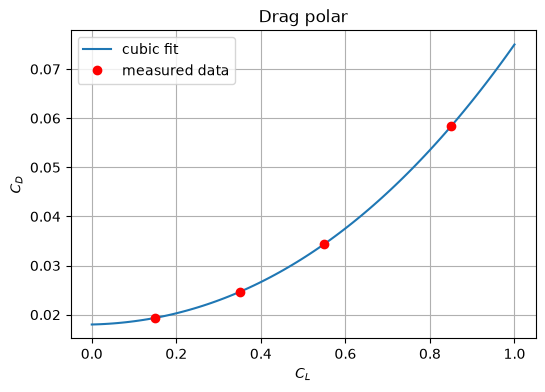

In [ ]:
CL_plot = np.linspace(0, 1, 100)
CD_fit = x2[0] + x2[1]*CL_plot + x2[2]*CL_plot**2 + x2[3]*CL_plot**3

plt.figure(figsize=(6, 4))
plt.plot(CL_plot, CD_fit, label="cubic fit")
plt.plot(CL, CD, "ro", label="measured data")
plt.xlabel("$C_L$")
plt.ylabel("$C_D$")
plt.title("Drag polar")
plt.grid(True)
plt.legend()
plt.show()